# Proyek 2: Agglomerative Hierarchical Clustering dengan Manhattan Distance (L1 Norm) pada BISINDO

**Metrik Jarak:** Manhattan Distance (L1 Norm / City-Block)  
**Metode Linkage:** Complete Linkage (Maximum Dissimilarity)  
**Representasi Fitur:** 127 Dimensi MediaPipe (42 Titik 3D + Is_Two_Handed)  
**Target Klaster:** K = 26 Klaster Alfabet BISINDO  
**Output Target:** `outputHAC/dendrogram_manhattan.png`, `outputHAC/cluster_manhattan.png`, `outputHAC/evaluasi_hac_manhattan.xlsx`

---

## 1. Landasan Teori & Formulasi Matematis

Jarak Manhattan berbasis akumulasi selisih nilai mutlak ortogonal per koordinat:
$$d_{\text{Manhattan}}(x, y) = \|x - y\|_1 = \sum_{i=1}^{127} |x_i - y_i|$$

Complete Linkage mengukur jarak terjauh antar-titik dalam metrik L1:
$$D(A, B) = \max_{x \in A, y \in B} \|x - y\|_1$$
Sifat linier metrik Manhattan mencegah penalti kuadratis berlebih akibat pergeseran sendi outlier.

In [1]:
# =======================================================================
# 1. SETUP LINGKUNGAN & PUSTAKA
# =======================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.dirname(os.path.abspath(__file__)) if '__file__' in locals() else os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "outputHAC")
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET_CLUSTERS = 26
RANDOM_STATE = 42

print(f"[INFO] Direktori: {BASE_DIR} | Target Klaster = {TARGET_CLUSTERS}")

[INFO] Direktori: E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC | Target Klaster = 26


In [2]:
# =======================================================================
# PEMUATAN DATASET BISINDO LANDMARKS (127 FITUR)
# =======================================================================
npz_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.npz")
csv_path = os.path.join(BASE_DIR, "dataset_bisindo_landmarks.csv")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=True)
    X = data['X'].astype(np.float32)
    labels = data['labels']
    df_meta = pd.DataFrame({'label': labels, 'is_two_handed': data['is_two_handed']})
elif os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    meta_cols = ['label', 'label_idx', 'filename', 'num_hands', 'is_flip']
    meta_present = [c for c in meta_cols if c in df_full.columns]
    df_meta = df_full[meta_present]
    feat_cols = [c for c in df_full.columns if c not in meta_cols]
    X = df_full[feat_cols].values.astype(np.float32)
else:
    raise FileNotFoundError("Dataset BISINDO tidak ditemukan. Jalankan extract_features.py.")

print(f"[INFO] Dataset BISINDO dimuat: {X.shape[0]} sampel, {X.shape[1]} dimensi fitur.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("[INFO] Fitur distandardisasi dengan StandardScaler.")

[INFO] Dataset BISINDO dimuat: 7893 sampel, 127 dimensi fitur.
[INFO] Fitur distandardisasi dengan StandardScaler.


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\dendrogram_manhattan.png'


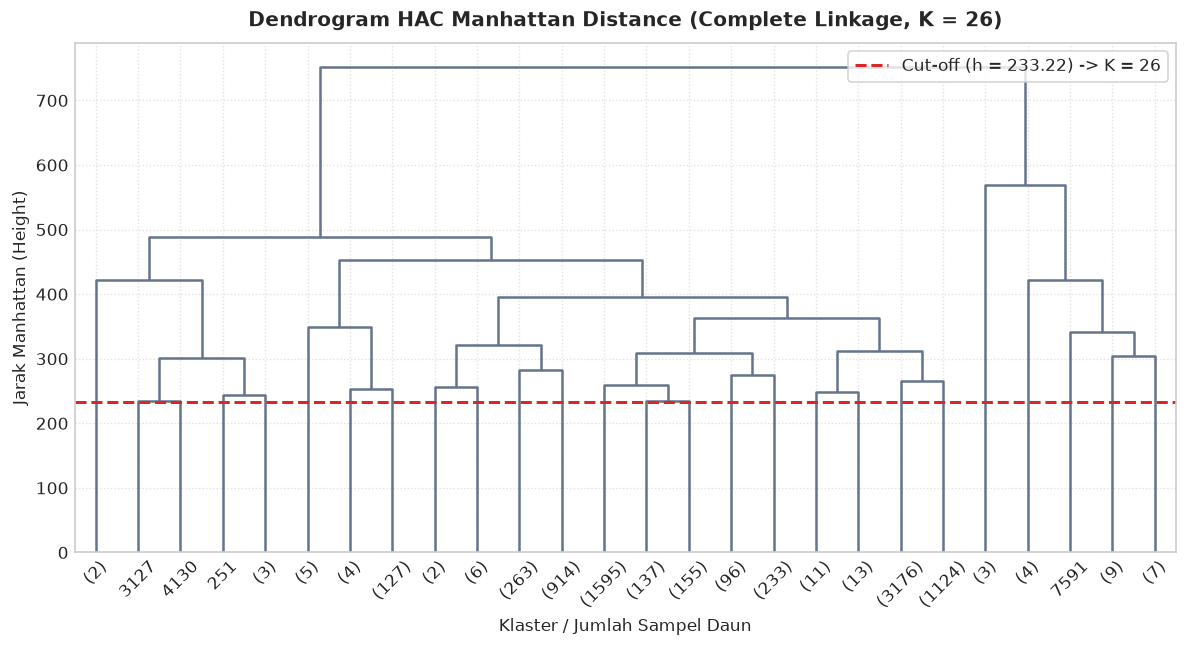

In [3]:
# =======================================================================
# 2. KONSTRUKSI LINKAGE DAN VISUALISASI DENDROGRAM MANHATTAN
# =======================================================================
t0 = time.perf_counter()
Z = linkage(X_scaled, method='complete', metric='cityblock')
runtime_linkage = time.perf_counter() - t0

k_idx = TARGET_CLUSTERS - 1
h_cut = (Z[-k_idx, 2] + Z[-(k_idx + 1), 2]) / 2.0

plt.figure(figsize=(10, 5.5))
ddata = dendrogram(
    Z,
    truncate_mode='lastp',
    p=TARGET_CLUSTERS,
    color_threshold=h_cut,
    above_threshold_color='#64748B',
    show_leaf_counts=True
)

plt.axhline(y=h_cut, color='#DC2626', linestyle='--', linewidth=1.8, label=f'Cut-off (h = {h_cut:.2f}) -> K = {TARGET_CLUSTERS}')
plt.title(f'Dendrogram HAC Manhattan Distance (Complete Linkage, K = {TARGET_CLUSTERS})', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Klaster / Jumlah Sampel Daun', fontsize=10)
plt.ylabel('Jarak Manhattan (Height)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()

dendro_path = os.path.join(OUTPUT_DIR, "dendrogram_manhattan.png")
plt.savefig(dendro_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{dendro_path}'")
plt.show()

In [4]:
# =======================================================================
# 3. EKSTRAKSI KLASTER DAN EVALUASI METRIK MANHATTAN
# =======================================================================
labels = fcluster(Z, t=TARGET_CLUSTERS, criterion='maxclust') - 1
n_found = len(np.unique(labels))

sil = float(silhouette_score(X_scaled, labels, metric='manhattan'))
db = float(davies_bouldin_score(X_scaled, labels))
ch = float(calinski_harabasz_score(X_scaled, labels))

df_res = pd.DataFrame([{
    'Distance Metric': 'Manhattan Distance (L1)',
    'Linkage': 'Complete Linkage',
    'Clusters (K)': n_found,
    'Cut-off Height (h)': round(h_cut, 3),
    'Silhouette Score (↑)': round(sil, 4),
    'Davies–Bouldin Index (↓)': round(db, 4),
    'Calinski–Harabasz Index (↑)': round(ch, 2),
    'Execution Time (s) (↓)': round(runtime_linkage, 4)
}])

print("\n" + "="*85)
print(df_res.to_string(index=False))
print("="*85)

excel_out = os.path.join(OUTPUT_DIR, "evaluasi_hac_manhattan.xlsx")
df_data_out = df_meta.copy()
df_data_out['cluster_manhattan'] = labels

with pd.ExcelWriter(excel_out, engine='openpyxl') as writer:
    df_res.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    df_data_out.to_excel(writer, sheet_name='Data_Terklaster', index=False)
print(f"[SAVE] Laporan Excel disimpan ke: '{excel_out}'")


        Distance Metric          Linkage  Clusters (K)  Cut-off Height (h)  Silhouette Score (↑)  Davies–Bouldin Index (↓)  Calinski–Harabasz Index (↑)  Execution Time (s) (↓)
Manhattan Distance (L1) Complete Linkage            26             233.217                 0.143                    1.2737                       349.85                  1.7076


[SAVE] Laporan Excel disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\evaluasi_hac_manhattan.xlsx'


[SAVE] Grafik disimpan ke: 'E:\Dokumen\Kuliah\Semester 5\Pembelajaran Mesin\UTS_Bisindo_Klasterisasi_Kelompok-1\HAC\outputHAC\cluster_manhattan.png'


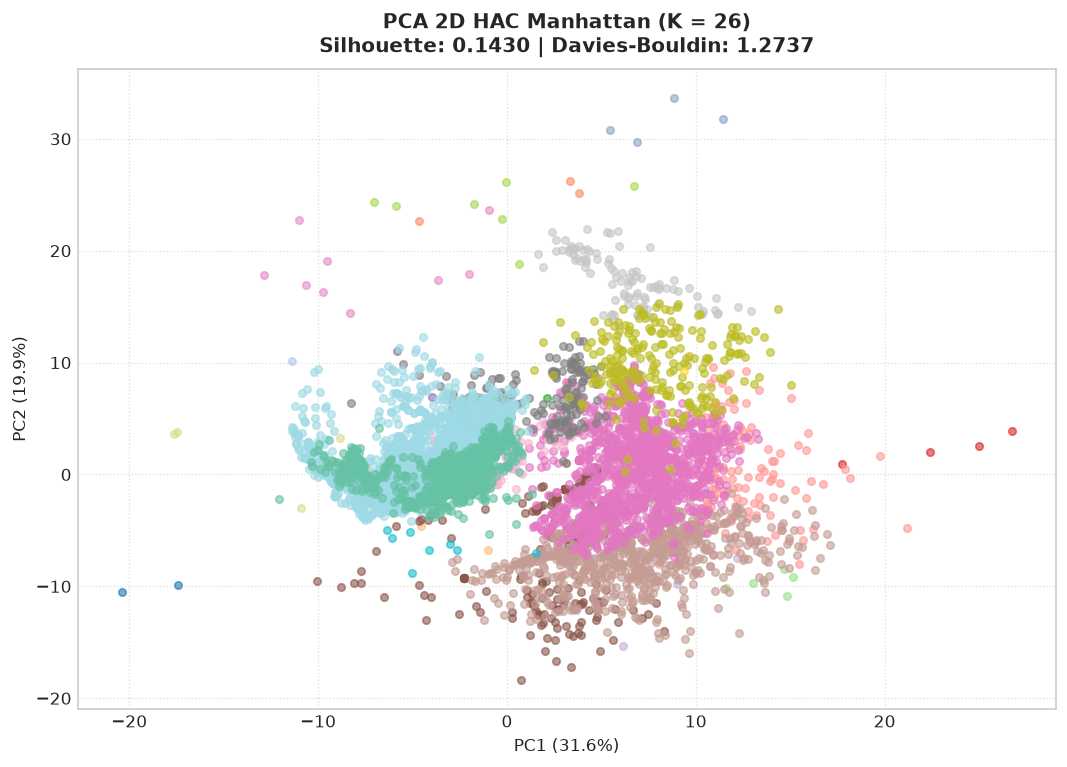

In [5]:
# =======================================================================
# 4. VISUALISASI PCA 2D KLASTERISASI HAC MANHATTAN
# =======================================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6.5))
palette = sns.color_palette("tab20", 20) + sns.color_palette("Set2", 6)

for k in range(n_found):
    mask = (labels == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[k % len(palette)], alpha=0.60, s=20)

plt.title(f'PCA 2D HAC Manhattan (K = {n_found})\nSilhouette: {sil:.4f} | Davies-Bouldin: {db:.4f}', fontsize=12, fontweight='bold', pad=10)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_manhattan.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SAVE] Grafik disimpan ke: '{cluster_path}'")
plt.show()